# Canadian case NTGS1 / NTGS2: fidelity porting against GEOtop 3.0

The snow+soil column of WHETGEO-1D in the **fidelity** configuration is run **heat only** (`soilWaterMode = Fixed`, as GEOtop's `WaterBalance = 0`). It is compared with **GEOtop 3.0 without canopy, corrected** (`casi/Canada_NTGS/sims/<case>_senza_chioma_corretta`) on four cases: two sites (NTGS1 peatland, NTGS2 hilltop) × two reanalyses (ERA5, JRA-3Q).

**Run setup**

- Hourly steps from 01/09/2020; comparison over **01/09/2021 – 01/09/2023**, after one year of warm-up as in GEOtop's project.
- Same 20 soil layers to 9.03 m, same initial temperature per layer, zero heat flux at the bottom.

**Forcing**

The forcing is GEOtop's own, recomputed from its input files by the temporary fidelity tools; it matches GEOtop's point output to 1e-6:

- precipitation × cos(slope) once, split at 1 / −3 °C;
- shortwave on the slope;
- the reanalysis longwave;
- pressure from the elevation.

**Fallback.** Without snow, the top of the soil is held at GEOtop's `Tsurface` (Dirichlet): the bare-soil energy balance now exists, but here GEOtop's surface temperature keeps the comparison on the snow and the soil.

**Ported for fidelity** (rounds 4–5): GEOtop's skin node (SURF-1/2), shortwave penetration (SNOW-7), thin-snow regime, snow–soil face conductance (SNOW-3), porosity cap (SNOW-6) and thin cells kept unshrunk. **Not ported:** delayed refreezing (STA-3) and GEOtop's emergency turbulence path, which never acts in these cases.

Nothing was tuned.

Run `cases/snowsoil/canada_ntgs/run.sh` first. This notebook reads `output/<case>/` and `geotop/<case>/reference.csv.gz`.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
CASE_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "cases", "snowsoil", "canada_ntgs"))
sys.path.insert(0, CASE_DIR)
import compare
pd.set_option("display.width", 200)
data = {c: compare.load(c) for c in compare.CASES}

## Comparison table

For scalar rows, the columns hold the porting−GEOtop bias and the RMSE. For peaks and maximum thaw they hold porting / GEOtop. For snow dates they hold porting − GEOtop [d] / GEOtop's date.

In [2]:
tables = {c: compare.compare(c).set_index(["quantity", "unit"]) for c in compare.CASES}
summary = pd.concat({c: t for c, t in tables.items()}, axis=1)
summary.round(2)

NTGS1_ERA5                                 NTGS1_JR3QG                                  NTGS2_ERA5                \
                                           porting-GEOtop bias / porting RMSE / GEOtop porting-GEOtop bias / porting RMSE / GEOtop porting-GEOtop bias / porting RMSE / GEOtop   
quantity                              unit                                                                                                                                       
HS daily                              mm                            0.84       1.36632                          1.04      1.474006                          0.96      1.474903   
SWE daily                             mm                            0.29       0.37789                          0.34      0.475494                          0.33      0.450855   
HS peak 2021-2022 (porting / GEOtop)  mm                          390.88    388.610988                        460.92    459.853533                        378.46    378.059889   
SWE peak 2021-2022 (porting / GEOtop) mm                           89.47     88.998912                         97.19     96.670955                         85.74     85.066524   
HS peak 2022-2023 (porting / GEOtop)  mm                          400.55    400.586083                        525.68    525.368993                        387.90    386.886944   
SWE peak 2022-2023 (porting / GEOtop) mm                          103.94    103.582504                        128.97    128.592875                         98.93     98.323008   
snow-on 2021-2022 (porting - GEOtop)  d                             0.00    2021-09-28                         -1.00    2021-09-24                          0.00    2021-09-28   
snow-off 2021-2022 (porting - GEOtop) d                             0.00    2022-05-26                          0.00    2022-05-28                          0.00    2022-05-28   
snow-on 2022-2023 (porting - GEOtop)  d                             0.00    2022-09-27                          0.00    2022-09-27                          0.00    2022-09-27   
snow-off 2022-2023 (porting - GEOtop) d                             0.00    2023-05-22                          1.00    2023-05-25                          0.00    2023-05-24   
Ts with snow, hourly                  K                            -0.01      0.495049                          0.02      0.379066                         -0.01      0.406167   
T 0.1 m hourly                        K                             0.04      0.284634                          0.02      0.290221                          0.02      0.240211   
T 0.1 m daily                         K                             0.04      0.279235                          0.02      0.285188                          0.02      0.233955   
T 0.1 m hourly, end of hour           K                             0.04      0.284634                          0.02      0.290221                          0.02      0.240211   
T 0.5 m hourly                        K                             0.13      0.335255                          0.11      0.336102                          0.09      0.275629   
T 0.5 m daily                         K                             0.13      0.333643                          0.11       0.33436                          0.09      0.273926   
T 0.5 m hourly, end of hour           K                             0.13      0.335255                          0.11      0.336102                          0.09      0.275629   
T 1.0 m hourly                        K                             0.13      0.332538                          0.09      0.289302                          0.07      0.256965   
T 1.0 m daily                         K                             0.13      0.332076                          0.09      0.288866                          0.07      0.256516   
T 1.0 m hourly, end of hour           K                             0.13      0.332538                          0.09      0.289302                

## Snow depth and SWE (daily means)

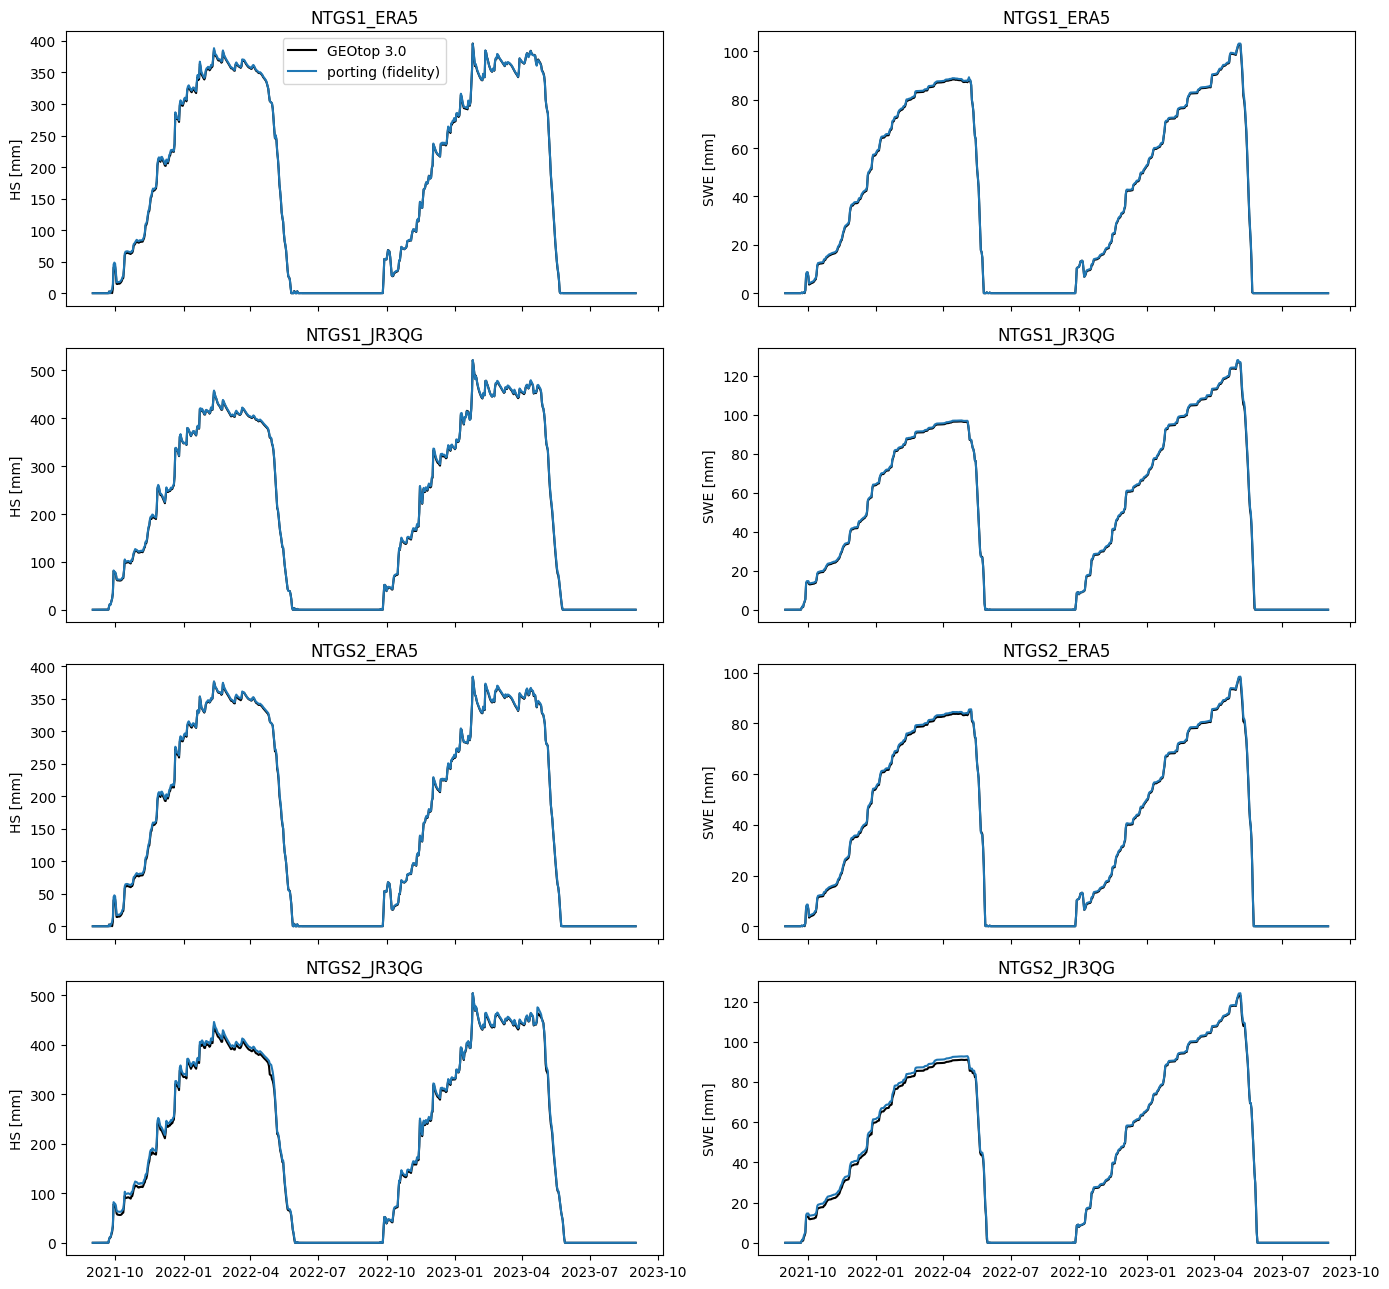

In [3]:
fig, axes = plt.subplots(4, 2, figsize=(14, 13), sharex=True)
for i, c in enumerate(compare.CASES):
    d = data[c].resample("D").mean()
    for j, q in enumerate(("HS", "SWE")):
        ax = axes[i, j]
        ax.plot(d.index, d["gt_" + q], "k", label="GEOtop 3.0")
        ax.plot(d.index, d["wg_" + q], "tab:blue", label="porting (fidelity)")
        ax.set_ylabel(q + " [mm]")
        ax.set_title(c)
axes[0, 0].legend()
fig.tight_layout()

## Soil temperature at 0.1, 0.5, 1, 2 and 4 m (daily means)

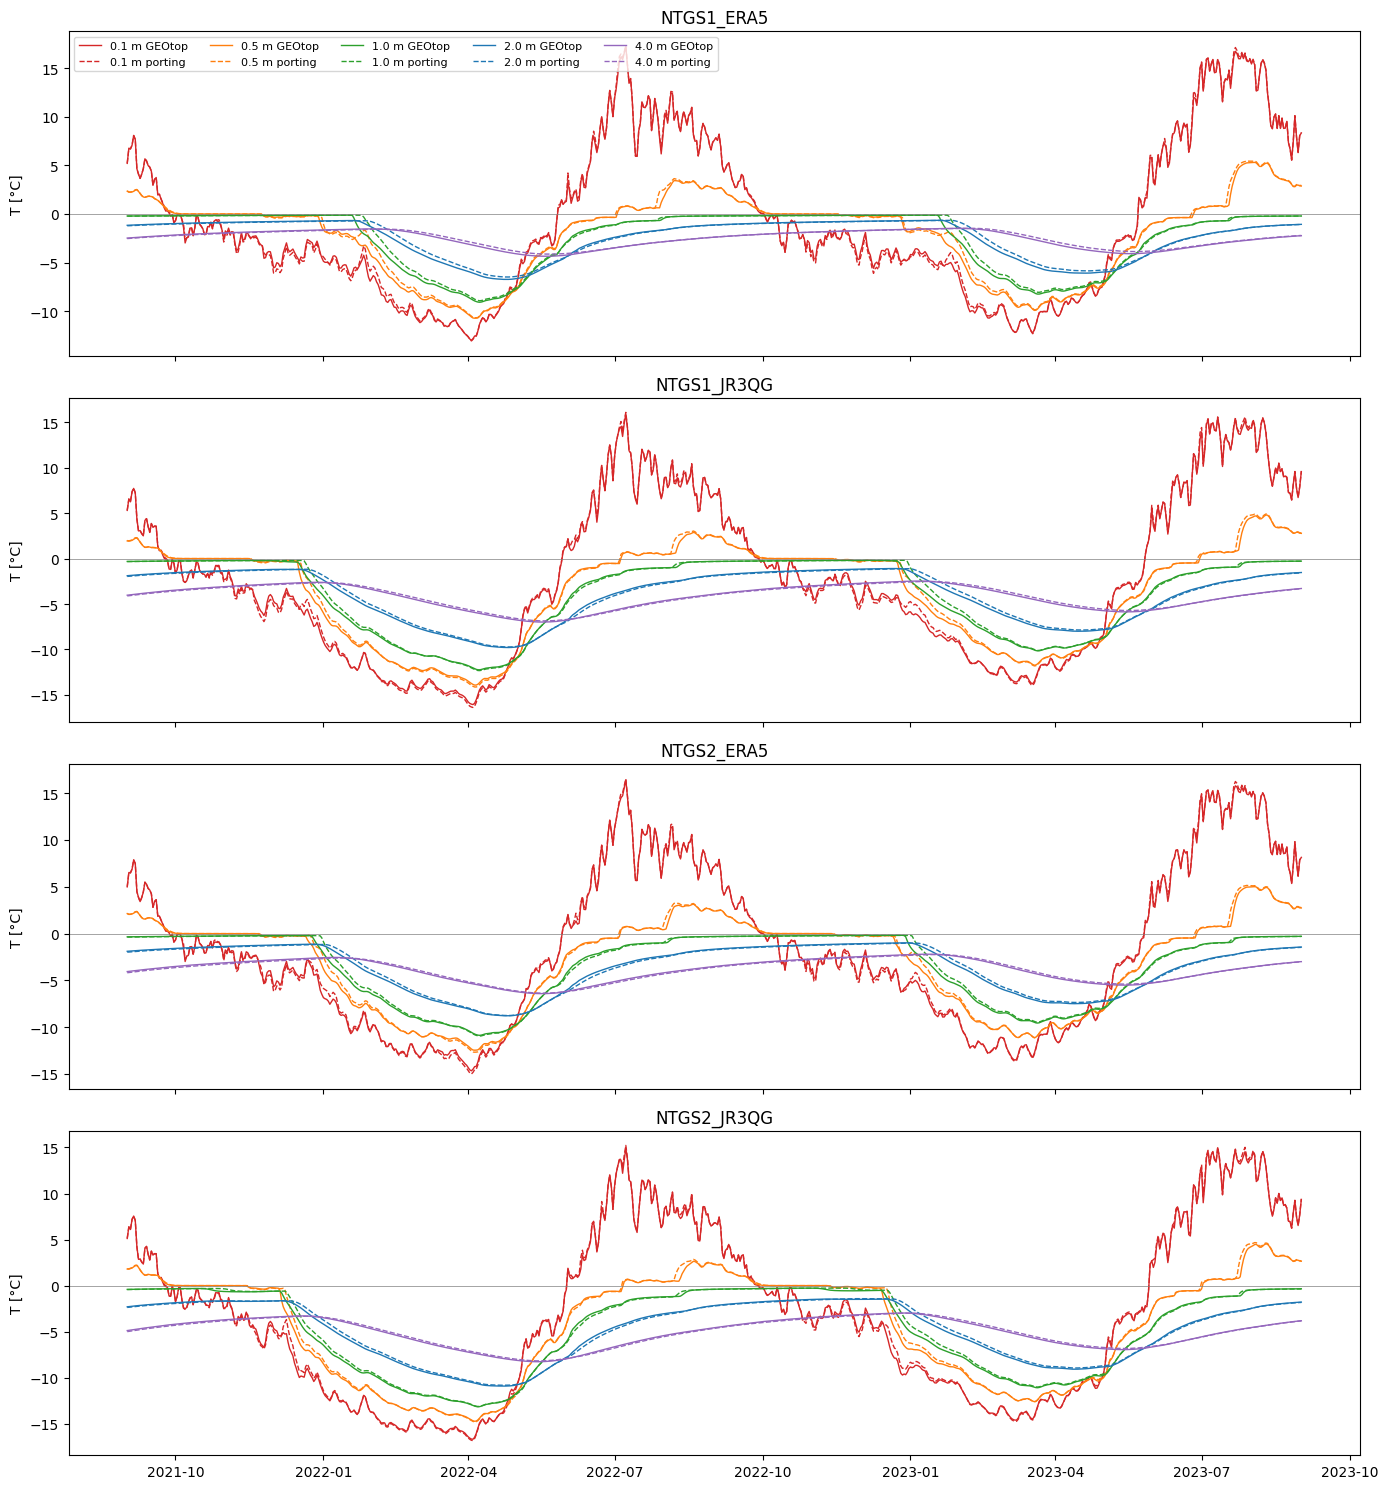

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(14, 15), sharex=True)
colors = dict(zip(compare.DEPTHS_MM, ["tab:red", "tab:orange", "tab:green", "tab:blue", "tab:purple"]))
for ax, c in zip(axes, compare.CASES):
    d = data[c].resample("D").mean()
    for z in compare.DEPTHS_MM:
        ax.plot(d.index, d["gt_T%d" % z], color=colors[z], lw=1, label="%.1f m GEOtop" % (z / 1000))
        ax.plot(d.index, d["wg_T%d" % z], color=colors[z], lw=1, ls="--", label="%.1f m porting" % (z / 1000))
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_ylabel("T [°C]")
    ax.set_title(c)
axes[0].legend(ncol=5, fontsize=8)
fig.tight_layout()

## Monthly bias of soil temperature, porting − GEOtop

The bias builds up in winter, under snow, and it is largest in spring at shallow depths. In summer, when the top is held at GEOtop's `Tsurface`, the shallow layers return to GEOtop's values; the deep layers keep part of the winter deficit.

In [5]:
rows = {}
for c in compare.CASES:
    m = data[c].resample("MS").mean()
    rows[c] = pd.DataFrame({"%.1f m" % (z / 1000): m["wg_T%d" % z] - m["gt_T%d" % z] for z in compare.DEPTHS_MM})
pd.concat(rows, axis=1).round(2)

NTGS1_ERA5                         NTGS1_JR3QG                         NTGS2_ERA5                         NTGS2_JR3QG                        
                          0.1 m 0.5 m 1.0 m 2.0 m 4.0 m       0.1 m 0.5 m 1.0 m 2.0 m 4.0 m      0.1 m 0.5 m 1.0 m 2.0 m 4.0 m       0.1 m 0.5 m 1.0 m 2.0 m 4.0 m
Date12[DDMMYYYYhhmm]                                                                                                                                              
2021-09-01                 0.04  0.04 -0.01 -0.05 -0.05        0.03  0.04 -0.01 -0.07 -0.08       0.03  0.03 -0.02 -0.08 -0.12        0.02  0.03 -0.02 -0.07 -0.11
2021-10-01                 0.03  0.00 -0.01 -0.05 -0.06       -0.05  0.00 -0.01 -0.07 -0.09       0.03  0.00 -0.02 -0.08 -0.13       -0.04  0.00  0.07 -0.06 -0.11
2021-11-01                -0.16  0.00 -0.01 -0.04 -0.05       -0.35 -0.03 -0.00 -0.06 -0.08      -0.14 -0.00 -0.02 -0.07 -0.11       -0.18 -0.02  0.07  0.03 -0.08
2021-12-01                -0.37  0.02 -0.01 -0.04 -0.05        0.19  0.54  0.53  0.12 -0.07      -0.10  0.25  0.18 -0.05 -0.10        0.51  0.80  0.62  0.26 -0.03
2022-01-01                 0.08  0.33  0.49  0.07 -0.05        0.18  0.34  0.46  0.44  0.09       0.39  0.57  0.65  0.41 -0.01        0.06  0.19  0.33  0.37  0.13
2022-02-01                 0.51  0.68  0.76  0.59  0.07       -0.17 -0.03  0.12  0.28  0.19      -0.06  0.08  0.22  0.31  0.13       -0.10  0.01  0.14  0.24  0.17
2022-03-01                 0.07  0.18  0.31  0.42  0.24       -0.24 -0.14 -0.02  0.16  0.19      -0.23 -0.10  0.04  0.17  0.14       -0.11 -0.04  0.06  0.15  0.15
2022-04-01                 0.04  0.08  0.15  0.28  0.26       -0.20 -0.17 -0.08  0.08  0.17      -0.17 -0.14 -0.06  0.05  0.10       -0.15 -0.07  0.01  0.10  0.13
2022-05-01                 0.13  0.11  0.10  0.16  0.22        0.11  0.01 -0.03  0.01  0.13       0.08  0.00 -0.04 -0.02  0.05        0.09  0.01 -0.03 -0.00  0.09
2022-06-01                 0.17 -0.04 -0.12 -0.13  0.07        0.20 -0.05 -0.20 -0.28 -0.05       0.15 -0.08 -0.24 -0.31 -0.12        0.18 -0.11 -0.27 -0.30 -0.08
2022-07-01                 0.14  0.22  0.01 -0.06  0.00        0.09  0.04 -0.05 -0.16 -0.10       0.06  0.04 -0.06 -0.16 -0.14        0.09  0.04 -0.07 -0.17 -0.13
2022-08-01                 0.09  0.14  0.01 -0.01  0.00        0.14  0.32  0.05 -0.06 -0.08       0.11  0.24  0.03 -0.06 -0.10        0.14  0.32  0.06 -0.05 -0.09
2022-09-01                 0.04  0.04 -0.01 -0.02  0.00        0.05  0.06 -0.01 -0.07 -0.07       0.03  0.04 -0.02 -0.06 -0.08        0.05  0.05 -0.02 -0.05 -0.07
2022-10-01                -0.05  0.01 -0.01 -0.03 -0.01       -0.06  0.01 -0.01 -0.08 -0.10      -0.05  0.00 -0.02 -0.06 -0.08       -0.06  0.00 -0.02 -0.07 -0.10
2022-11-01                -0.24 -0.01 -0.01 -0.02 -0.02       -0.23 -0.02 -0.01 -0.07 -0.09      -0.21 -0.02 -0.01 -0.05 -0.08       -0.23 -0.02  0.18  0.00 -0.08
2022-12-01                -0.35 -0.00 -0.01 -0.02 -0.02       -0.12  0.26  0.26 -0.03 -0.09      -0.23  0.04  0.05 -0.05 -0.07        0.32  0.65  0.47  0.16 -0.04
2023-01-01                 0.04  0.29  0.49  0.09 -0.02        0.63  0.77  0.81  0.51  0.02       0.42  0.62  0.70  0.35 -0.01        0.25  0.37  0.47  0.44  0.11
2023-02-01                 0.36  0.55  0.66  0.56  0.10        0.01  0.16  0.30  0.39  0.19      -0.02  0.11  0.25  0.33  0.14       -0.04  0.08  0.21  0.30  0.19
2023-03-01                 0.01  0.11  0.24  0.37  0.25       -0.13 -0.05  0.07  0.24  0.22      -0.06  0.01  0.11  0.20  0.16       -0.08 -0.01  0.09  0.19  0.18
2023-04-01                 0.04  0.08  0.14  0.25  0.26       -0.03 -0.02  0.03  0.14  0.19       0.04  0.05  0.08  0.13  0.14        0.08  0.07  0.09  0.13  0.15
2023-05-01                 0.12  0.05  0.04  0.12  0.22        0.10  0.03  0.00  0.05  0.14       0.16  0.06  0.03  0.05  0.10        0.12  0.08  0.05  0.06  0.11
2023-06-01                 0.14  0.03 -0.04 -0.05  0.10        0.15  0.03 -0.08 -0.12  0.02       0.14  0.04 

## Surface temperature with snow (hourly, both models with snow)

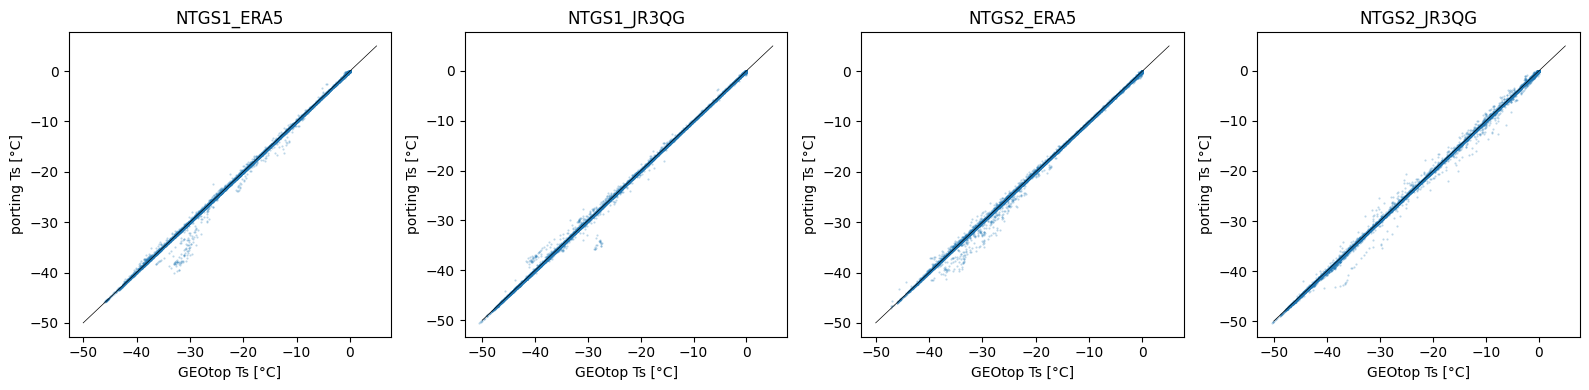

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, compare.CASES):
    d = data[c]
    both = (d.gt_SWE > compare.SNOW_SWE) & (d.wg_SWE > compare.SNOW_SWE)
    ax.plot(d.loc[both, "gt_Ts"], d.loc[both, "wg_Ts"], ".", ms=1, alpha=0.3)
    ax.plot([-50, 5], [-50, 5], "k", lw=0.5)
    ax.set_xlabel("GEOtop Ts [°C]"); ax.set_ylabel("porting Ts [°C]"); ax.set_title(c)
fig.tight_layout()

## Thaw depth (GEOtop's `lowest_thawed_soil_depth` and the same algorithm on the porting's profiles)

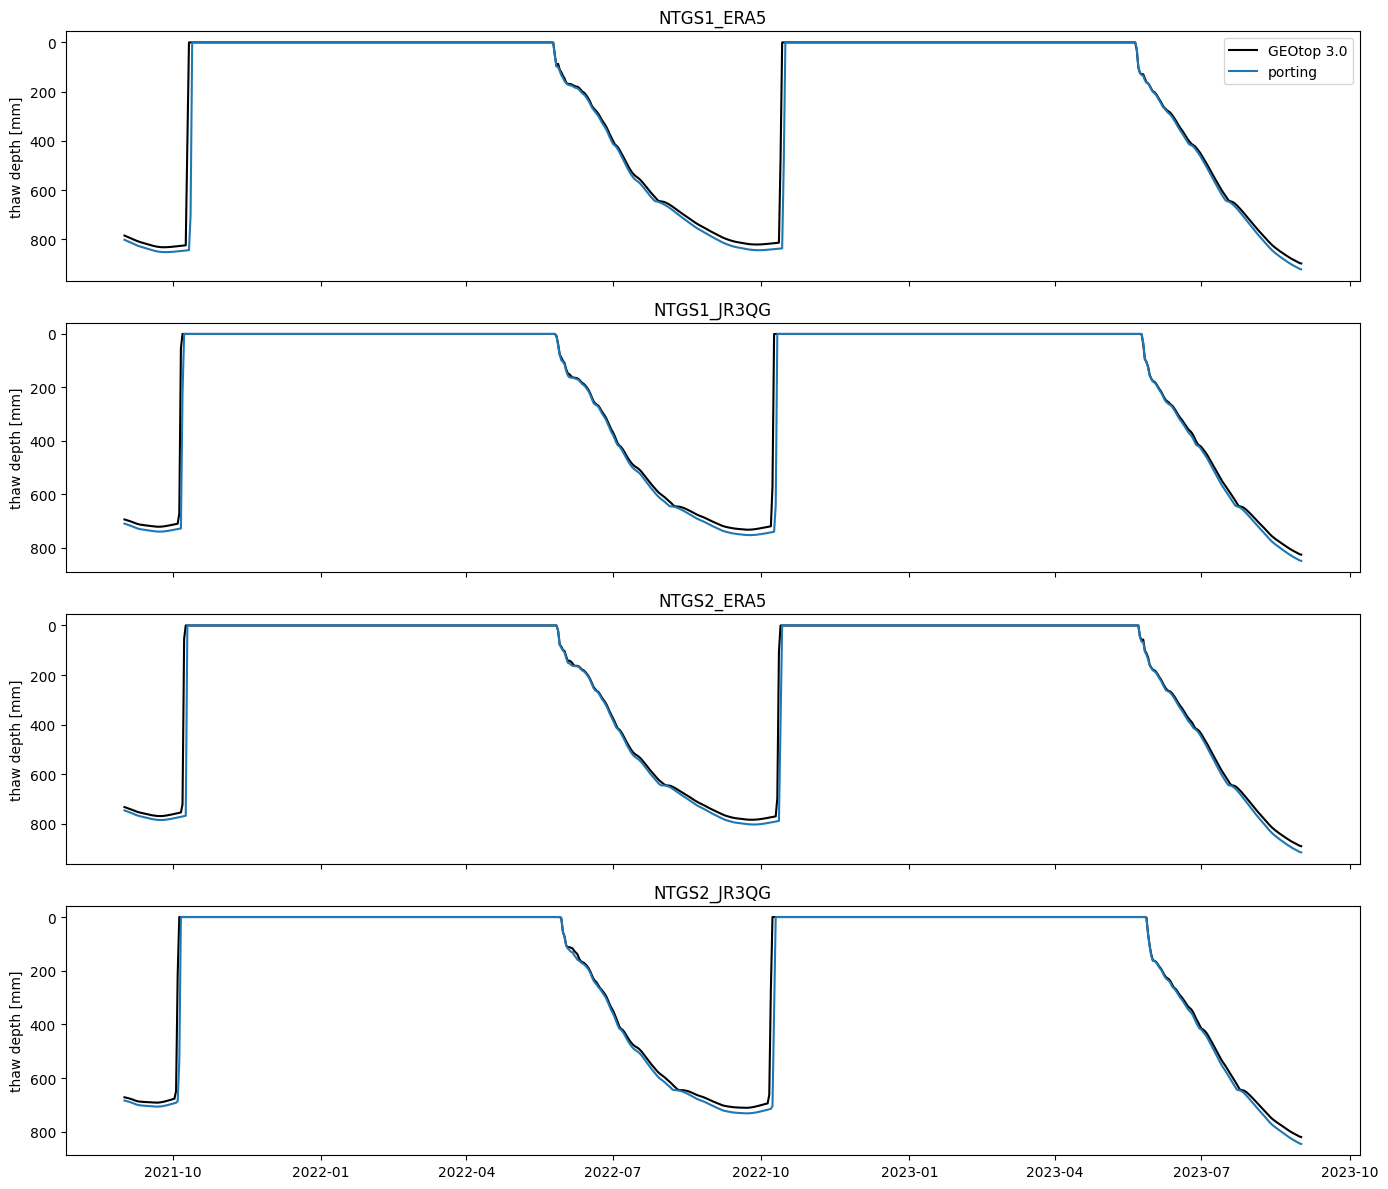

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
for ax, c in zip(axes, compare.CASES):
    d = data[c].resample("D").mean()
    ax.plot(d.index, d.gt_thaw, "k", label="GEOtop 3.0")
    ax.plot(d.index, d.wg_thaw, "tab:blue", label="porting")
    ax.invert_yaxis(); ax.set_ylabel("thaw depth [mm]"); ax.set_title(c)
axes[0].legend()
fig.tight_layout()

## Attribution of the differences

With the skin node and the shortwave penetration the porting follows GEOtop:

- **Snow:** SWE daily RMSE 0.4–1.0 mm, peaks within 0.5–2 %, snow-on and snow-off on the same day (one day off in two of the sixteen dates).
- **Surface with snow:** bias within ±0.02 K, RMSE 0.4–0.5 K.
- **Soil:** bias +0.02 to +0.13 K, daily RMSE 0.23–0.35 K at 0.1–1 m and 0.10–0.13 K at 4 m. What is left: 0.5–0.8 K warmer at 0.5–1 m in January–February, up to 0.35 K colder in the top 0.1 m in November–December.
- **Thaw depth:** the summer maximum is 16–26 mm deeper than GEOtop's.

**How the 1–1.6 K cold soil of the first runs was closed** (soil bias at 0.1 / 1 / 4 m, NTGS1 ERA5):

| porting | soil bias [K] | SWE daily RMSE | snow-off |
|---|---|---|---|
| first runs | −1.42 / −1.18 / −1.02 | 5.7 mm | +3, +5 d |
| + GEOtop's face conductance, thin snow, porosity cap | −1.58 / −1.33 / −1.15 | 5.8 mm | +3, +4 d |
| + skin node | −0.51 / −0.35 / −0.31 | 4.0 mm | +2, +2 d |
| + shortwave penetration | +0.04 / +0.13 / +0.06 | 0.38 mm | 0, 0 d |

1. **Skin node.** An instrumented GEOtop 3.0 (`INDAGINE_SUOLO.md` in the case folder of the GEO2GEO workspace) showed that GEOtop without its skin is 1.07–1.32 K colder than with it: the surface flux reaches the centre of the top layer through half of its thickness, and without that resistance the pack insulates less. GEOtop freezes the resistances at the top-layer temperature at the start of the step, which is where the negative Obukhov lengths of 12–45 % of the snow hours come from; the porting does the same.
2. **Shortwave penetration.** With the skin, the remaining deficit grew from February to April with the sun: in December–January the porting's H matched GEOtop's, in February–April it was 1.6–3.6 W m⁻² smaller. With more than one snow layer GEOtop gives no shortwave to the skin (`rad_snow_absorption`, `radiation.cc:582-613`): the top layer absorbs it and starts the next step warmer, and the colder skin draws more heat from the air.
3. **Not the emergency turbulence path.** The recomputation without stable correction after 10 Newton iterations below −50 °C (`energy.balance.cc:57-58, 1835, 2618-2621`) never fires in these cases (0 of about 17 000 snow steps; switched off, GEOtop's outputs are byte-identical).
4. **Not the conductivities within the step.** Refreshing them three times per step (`-DheatPicardIterations=3`) moves the soil by less than 0.002 K.

**Numerics.**

- About 65–95 s per case: 3 years hourly, 20 soil cells, 26 280 steps.
- NTGS1 JRA-3Q and NTGS2 JRA-3Q have 1 and 3 rejected steps, each accepted after halving; no step is degraded.
- In NTGS1 JRA-3Q, one hour of 5 October 2021 (a saturated peat cell forming its first ice exactly at its melting temperature) needs a second polish round of the heat driver: Newton converges only linearly there (743 → 9.4 → 0.005 times the per-cell bound).
